In [3]:
#%matplotlib inline
import numpy as np
from collections import deque
from scipy.spatial import cKDTree
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import EllipseCollection
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle
from matplotlib.ticker import FuncFormatter
from IPython.display import HTML

#test change


Animation size has reached 20988976 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


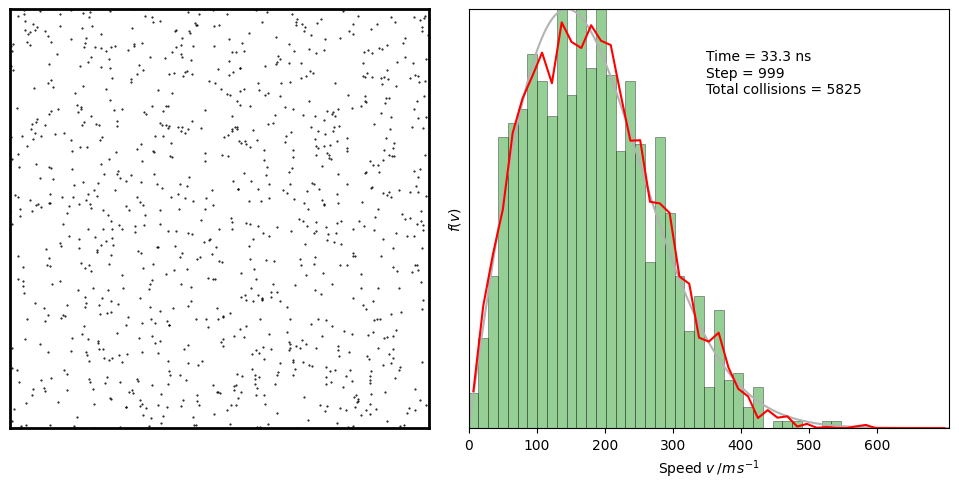

In [ ]:

mpl.rcParams['animation.embed_limit'] = 200
X, Y = 0, 1
class MDSimulation:
    """2D hard-disk gas of identical particles in a unit box."""
 
    def __init__(self, pos, vel, r, m):
        self.pos = np.asarray(pos, dtype=float)
        self.vel = np.asarray(vel, dtype=float)
        self.n = self.pos.shape[0]
        self.r = r
        self.m = m
        self.nsteps = 0
        self.total_collisions = 0
 
    def advance(self, dt):
        """Advance by dt; return the number of collisions that occurred."""
        self.nsteps += 1
        self.pos += self.vel * dt
 
        # KD-tree finds all overlapping pairs without an n x n matrix.
        pairs = cKDTree(self.pos).query_pairs(2 * self.r, output_type='ndarray')
        ncoll = 0
        for i, j in pairs:
            rel_pos = self.pos[i] - self.pos[j]
            rel_vel = self.vel[i] - self.vel[j]
            dot = rel_vel @ rel_pos
            if dot >= 0:            # already separating: no collision
                continue
            # Equal masses, elastic: swap the velocity components along the
            # line of centres.
            dv = dot / (rel_pos @ rel_pos) * rel_pos
            self.vel[i] -= dv
            self.vel[j] += dv
            ncoll += 1
        self.total_collisions += ncoll
 
        # Walls: reflect only if moving towards the wall, then clip position.
        r = self.r
        hit_l = (self.pos[:, X] < r) & (self.vel[:, X] < 0)
        hit_r = (self.pos[:, X] > 1 - r) & (self.vel[:, X] > 0)
        hit_b = (self.pos[:, Y] < r) & (self.vel[:, Y] < 0)
        hit_t = (self.pos[:, Y] > 1 - r) & (self.vel[:, Y] > 0)
        self.vel[hit_l | hit_r, X] *= -1
        self.vel[hit_b | hit_t, Y] *= -1
        np.clip(self.pos, r, 1 - r, out=self.pos)
        return ncoll

# Number of particles.
N = 1000
SCENARIO = 'hot_cold'       # 'hot_cold' (left fast, right slow) or 'uniform'
R_PHYS = 0.004              # collision radius (box is 1 x 1; exaggerated vs. real Ar)
R_DRAW = 0.006              # drawn radius (purely visual)
SUBSTEPS = 4                # physics sub-steps per animation frame
FPS = 30
FRAMES = 700
IAV_START = 150             # frame at which speed-histogram averaging starts
TEMP_KICKS = {450: 1.5}     # {frame: velocity scale factor}; set {} to disable
TRAIL_LEN = 300             # length of the tracer trail (frames)
NBARS = 40 

# Units: distance scaled by rscale, time by tscale (ns), as in the original.
rscale, tscale = 5.e6, 1e9
UNIT = rscale / tscale                      # scaled speed -> m/s is v / UNIT
sbar = 353 * UNIT                           # Ar rms speed at 300 K, scaled
dt = 1 / FPS


rng = np.random.default_rng()
pos = rng.random((N, 2))
theta = rng.random(N) * 2 * np.pi
if SCENARIO == 'hot_cold':
    scale = np.where(pos[:, X] < 0.5, 1.5, 0.5)
else:
    scale = np.ones(N)
s0 = sbar * scale * rng.random(N)
vel = (s0 * np.array((np.cos(theta), np.sin(theta)))).T
sim = MDSimulation(pos, vel, R_PHYS, m=1)

def get_speeds(v):
    return np.hypot(v[:, X], v[:, Y])
 
 
def mean_KE():
    """Mean kinetic energy per particle (scaled units)."""
    return 0.5 * sim.m * np.mean(get_speeds(sim.vel) ** 2)
 
 
KE0 = mean_KE()
vrms0 = np.sqrt(2 * KE0 / sim.m)
kmax = max([1.0] + list(TEMP_KICKS.values()))
VMAX = 3 * vrms0 * kmax                     # upper speed limit of the plots
VCOMP = 0.8 * VMAX     

to_ms = FuncFormatter(lambda v, _: f'{v / UNIT:.0f}')

fig = plt.figure(figsize=(14, 7.5), dpi=80)
gs = fig.add_gridspec(2, 3, width_ratios=[1.1, 1, 1], wspace=0.30, hspace=0.42,
                      left=0.03, right=0.93, top=0.90, bottom=0.08)
 
box_ax = fig.add_subplot(gs[:, 0], aspect='equal', autoscale_on=False)
box_ax.set(xlim=(0, 1), ylim=(0, 1), xticks=[], yticks=[])
for sp in box_ax.spines.values():
    sp.set_linewidth(2)
 
speed_ax = fig.add_subplot(gs[0, 1])
vx_ax = fig.add_subplot(gs[0, 2])
phase_ax = fig.add_subplot(gs[1, 1], aspect='equal')
diag_ax = fig.add_subplot(gs[1, 2])
H_ax = diag_ax.twinx()
 
# --- Box: particles coloured by speed, plus a tracer particle and its trail.
ec_kwargs = dict(widths=2 * R_DRAW, heights=2 * R_DRAW, angles=0, units='xy',
                 offsets=sim.pos, cmap='coolwarm')
try:
    particles = EllipseCollection(offset_transform=box_ax.transData, **ec_kwargs)
except TypeError:                                    # matplotlib < 3.6
    particles = EllipseCollection(transOffset=box_ax.transData, **ec_kwargs)
particles.set_array(get_speeds(sim.vel))
particles.set_clim(0, 2 * vrms0)
box_ax.add_collection(particles)
 
trail = deque(maxlen=TRAIL_LEN)
trail_line, = box_ax.plot([], [], lw=1.0, c='k', alpha=0.8, zorder=3)
tracer, = box_ax.plot([], [], 'o', ms=7, mfc='yellow', mec='k', mew=1.2, zorder=4)
label = box_ax.text(0.5, 1.015, '', transform=box_ax.transAxes, ha='center',
                    va='bottom', fontsize=10)
 
# --- Speed histogram + exact 2D Maxwell-Boltzmann + running average.
bins = np.linspace(0, VMAX, NBARS + 1)
sgrid = (bins[1:] + bins[:-1]) / 2
dbin = bins[1] - bins[0]
hist0, _ = np.histogram(get_speeds(sim.vel), bins, density=True)
bars = speed_ax.bar(sgrid, hist0, width=dbin, color='tab:green', alpha=0.5,
                    ec='k', lw=0.5)
sgrid_hi = np.linspace(0, VMAX, 300)
mb_line, = speed_ax.plot(sgrid_hi, np.zeros_like(sgrid_hi), c='0.45',
                         label='Maxwell-Boltzmann')
mb_est_line, = speed_ax.plot([], [], c='r', label='time average')
speed_ax.set(xlim=(0, VMAX), ylim=(0, 1.3 * np.sqrt(sim.m / KE0 / np.e)),
             yticks=[], xlabel='Speed $v\\,/\\,\\mathrm{m\\,s^{-1}}$',
             title='Speed distribution $f(v)$')
speed_ax.xaxis.set_major_formatter(to_ms)
speed_ax.legend(loc='upper right', fontsize=8, frameon=False)
 
# --- Velocity component histogram vs. Gaussian.
vbins = np.linspace(-VCOMP, VCOMP, NBARS + 1)
vcent = (vbins[1:] + vbins[:-1]) / 2
vbin_w = vbins[1] - vbins[0]
vh0, _ = np.histogram(sim.vel[:, X], vbins, density=True)
vx_bars = vx_ax.bar(vcent, vh0, width=vbin_w, color='tab:blue', alpha=0.5,
                    ec='k', lw=0.5)
vgrid = np.linspace(-VCOMP, VCOMP, 300)
gauss_line, = vx_ax.plot(vgrid, np.zeros_like(vgrid), c='0.45')
sigma0 = np.sqrt(KE0 / sim.m)
vx_ax.set(xlim=(-VCOMP, VCOMP), ylim=(0, 1.6 / (sigma0 * np.sqrt(2 * np.pi))),
          yticks=[], xlabel='$v_x\\,/\\,\\mathrm{m\\,s^{-1}}$',
          title='One component is Gaussian')
vx_ax.xaxis.set_major_formatter(to_ms)
 
# --- Phase space (vx, vy).
phase = phase_ax.scatter(sim.vel[:, X], sim.vel[:, Y], c=get_speeds(sim.vel),
                         cmap='coolwarm', vmin=0, vmax=2 * vrms0, s=4)
rms_circle = Circle((0, 0), vrms0, fill=False, ls='--', ec='0.4', lw=1)
phase_ax.add_patch(rms_circle)
phase_ax.set(xlim=(-VCOMP, VCOMP), ylim=(-VCOMP, VCOMP),
             xlabel='$v_x$', ylabel='$v_y$', title='Velocity space')
phase_ax.set_xticks([])
phase_ax.set_yticks([])
 
# --- Diagnostics: distance to MB (log) and Boltzmann H-function.
inst_line, = diag_ax.plot([], [], c='tab:blue', alpha=0.45, lw=1,
                          label='$L_1$ (instantaneous)')
avg_line, = diag_ax.plot([], [], c='r', lw=1.5, label='$L_1$ (averaged)')
H_line, = H_ax.plot([], [], c='tab:purple', lw=1.2, label='$H$')
Href_line, = H_ax.plot([], [], c='tab:purple', ls='--', lw=1, label='$H$ (MB)')
diag_ax.set(xlim=(0, FRAMES), ylim=(5e-3, 2), yscale='log',
            xlabel='Frame', title='Approach to equilibrium')
diag_ax.set_ylabel('$L_1$ distance to MB')
H_ax.set_ylabel('$H=\\int f\\ln f\\,dv$', color='tab:purple')
H_ax.tick_params(axis='y', colors='tab:purple')
h1, l1 = diag_ax.get_legend_handles_labels()
h2, l2 = H_ax.get_legend_handles_labels()
diag_ax.legend(h1 + h2, l1 + l2, fontsize=7, loc='upper right', frameon=False)
 
# ----------------------------------------------------------------------------
# Equilibrium reference (recomputed whenever the temperature changes)
# ----------------------------------------------------------------------------
state = dict(f_bins=None, H_mb=None, avg_from=IAV_START, mb_est=np.zeros(NBARS),
             smooth=None)
inst_hist, avg_hist, H_hist, Href_hist = [], [], [], []
 
 
def H_of(h):
    h = h[h > 0]
    return np.sum(h * np.log(h)) * dbin
 
 
def set_reference():
    """Update every 'exact equilibrium' curve to the current mean KE."""
    KE = mean_KE()
    a = sim.m / 2 / KE
    state['f_bins'] = 2 * a * sgrid * np.exp(-a * sgrid ** 2)
    state['H_mb'] = H_of(state['f_bins'])
    mb_line.set_ydata(2 * a * sgrid_hi * np.exp(-a * sgrid_hi ** 2))
    sigma = np.sqrt(KE / sim.m)
    gauss_line.set_ydata(np.exp(-vgrid ** 2 / (2 * sigma ** 2))
                         / (sigma * np.sqrt(2 * np.pi)))
    rms_circle.set_radius(np.sqrt(2 * KE / sim.m))
 
 
set_reference()
 
 
# ----------------------------------------------------------------------------
# Animation
# ----------------------------------------------------------------------------
def init_anim():
    particles.set_offsets(sim.pos)
    return particles,
 
 
def animate(i):
    # Optional "temperature knob": rescale all velocities at chosen frames.
    if i in TEMP_KICKS:
        sim.vel *= TEMP_KICKS[i]
        set_reference()
        state['avg_from'] = i + 80          # restart the time average
        state['mb_est'][:] = 0
 
    ncoll = 0
    for _ in range(SUBSTEPS):
        ncoll += sim.advance(dt / SUBSTEPS)
 
    speeds = get_speeds(sim.vel)
 
    # Box.
    particles.set_offsets(sim.pos)
    particles.set_array(speeds)
    trail.append(sim.pos[0].copy())
    xy = np.array(trail)
    trail_line.set_data(xy[:, 0], xy[:, 1])
    tracer.set_data([sim.pos[0, X]], [sim.pos[0, Y]])
    label.set_text(f'Time = {i * dt:.2f} ns     T/T$_0$ = {mean_KE() / KE0:.2f}\n'
                   f'collisions/frame = {ncoll}     total = {sim.total_collisions}')
 
    # Speed histogram, running average.
    hist, _ = np.histogram(speeds, bins, density=True)
    for bar, h in zip(bars, hist):
        bar.set_height(h)
    if i >= state['avg_from']:
        n = i - state['avg_from'] + 1
        state['mb_est'] += (hist - state['mb_est']) / n
        mb_est_line.set_data(sgrid, state['mb_est'])
        avg_d = np.sum(np.abs(state['mb_est'] - state['f_bins'])) * dbin
    else:
        mb_est_line.set_data([], [])
        avg_d = np.nan
 
    # Component histogram.
    vh, _ = np.histogram(sim.vel[:, X], vbins, density=True)
    for bar, h in zip(vx_bars, vh):
        bar.set_height(h)
 
    # Velocity space.
    phase.set_offsets(sim.vel)
    phase.set_array(speeds)
 
    # Diagnostics.
    inst_hist.append(np.sum(np.abs(hist - state['f_bins'])) * dbin)
    avg_hist.append(avg_d)
    # H from an exponentially smoothed histogram (raw bins are too noisy).
    state['smooth'] = hist if state['smooth'] is None else \
        0.85 * state['smooth'] + 0.15 * hist
    H_hist.append(H_of(state['smooth']))
    Href_hist.append(state['H_mb'])
    frames_x = np.arange(len(inst_hist))
    inst_line.set_data(frames_x, inst_hist)
    avg_line.set_data(frames_x, avg_hist)
    H_line.set_data(frames_x, H_hist)
    Href_line.set_data(frames_x, Href_hist)
    H_ax.relim()
    H_ax.autoscale_view(scalex=False)
 
    return particles, trail_line, tracer, label, mb_est_line, phase
 
 
anim = FuncAnimation(fig, animate, frames=FRAMES, interval=1000 / FPS,
                     blit=False, init_func=init_anim)
 
# In a notebook: show the animation inline (avoid a duplicate static figure).
# For a file instead, comment these out and use e.g.
#   anim.save('boltzmann.mp4', fps=FPS, dpi=100)               # needs ffmpeg
#   anim.save('boltzmann.gif', writer='pillow', fps=FPS)
plt.close(fig)
HTML(anim.to_jshtml())

